# Plan-and-Execute

복잡한 작업을 단계별로 계획하고 실행하며, 중간 결과에 따라 계획을 수정하는 Plan-and-Execute 패턴을 배운다.

In [1]:
import operator
from typing import Annotated, TypedDict, Union

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field


load_dotenv()

MODEL_NAME = "gemini-3.6-flash"

### Plan-and-Execute란

Plan-and-Execute는 먼저 전체 계획을 세운 뒤 각 단계를 실행하는 패턴이다. 실행 결과를 검토하고 필요에 따라 남은 계획을 수정할 수 있다.

| 구분 | ReAct | Plan-and-Execute |
|---|---|---|
| 계획 범위 | 매 순간 다음 행동 결정 | 전체 계획을 먼저 수립 |
| 장점 | 단순하고 빠름 | 복잡한 목표와 제약 조건 처리에 유리 |
| 단점 | 전체 흐름을 놓칠 수 있음 | 계획과 재계획 비용 발생 |
| 적합한 작업 | 단일 조회, 간단한 질의 | 조사, 비교, 일정 설계, 보고서 작성 |

```text
입력 → Planner → Executor → Replanner → Executor → ... → 최종 응답
```

Planner는 실행할 단계 목록을 만들고, Executor는 현재 계획의 첫 단계를 수행한다. Replanner는 실행 결과가 충분한지 판단하여 종료하거나 남은 계획을 교체한다.

### State와 출력 모델 정의

Plan-and-Execute에서는 현재 계획뿐 아니라 완료된 단계와 최종 응답도 추적해야 한다. Planner와 Replanner의 출력은 Pydantic 모델로 정의한다.

| 필드 | 타입 | 역할 |
|---|---|---|
| `input` | `str` | 사용자의 원래 요청 |
| `plan` | `list[str]` | 앞으로 실행할 단계 |
| `past_steps` | `list[tuple[str, str]]` | `(실행한 단계, 실행 결과)` 튜플의 목록 |
| `response` | `str` | 사용자에게 전달할 최종 응답 |

`past_steps`는 실행 이력을 보존해야 하므로 `operator.add` reducer로 누적한다. `plan`은 Replanner가 남은 계획 전체를 바꿀 수 있도록 reducer 없이 덮어쓴다.

In [2]:
llm = ChatGoogleGenerativeAI(model=MODEL_NAME)

class PlanExecuteState(TypedDict):
    input: str
    plan: list[str]
    past_steps: Annotated[list[tuple[str, str]], operator.add]
    response: str

class Plan(BaseModel):
    """앞으로 수행할 계획"""

    steps: list[str] = Field(description="순서대로 수행할 단계")


class Response(BaseModel):
    """사용자에게 전달할 최종 응답"""

    response: str = Field(description="검색 결과를 반영한 최종 여행 계획")


class ReplanDecision(BaseModel):
    """Replanner가 선택한 다음 결정"""

    decision: Union[Plan, Response]

    # 따로 두지 않는 이유는 두 응답이 다 나올 수 있기 때문에
    # plan : Plan
    # response : Response

### Planner

Planner는 사용자 요청을 구체적이고 실행 가능한 검색 단계로 나눈다. 한 단계에는 하나의 조사 목표만 포함한다.

In [3]:
planner_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """당신은 여행 요청을 실행 계획으로 만드는 Planner입니다.
각 단계는 Google Search로 조사할 수 있는 구체적인 작업이어야 합니다.
교통, 숙박, 관광지 운영 정보, 식당, 예산 검증처럼 서로 다른 조사 목표를 나누세요.
실행하지 않은 결과를 미리 판단하지 마세요.
계획은 최대 5단계로 작성하세요.""",
    ),
    ("human", "{input}"),
])

planner = planner_prompt | llm.with_structured_output(Plan)


def plan_step(state: PlanExecuteState):
    """사용자 요청을 바탕으로 초기 계획을 생성한다."""
    result = planner.invoke({"input": state["input"]})
    return {"plan": result.steps}

### Executor

Executor는 현재 계획의 첫 단계를 수행한다. Google Search가 연결된 Gemini를 사용해 최신 여행 정보를 조사하고 출처 URL과 함께 결과를 정리한다.

In [ ]:
search_llm = llm.bind_tools([{"google_search": {}}])

def execute_step(state: PlanExecuteState):
    """현재 계획의 첫 단계를 Google Search로 실행한다."""
    current_step = state["plan"][0]

    past_context = ""
    if state.get("past_steps"):
        past_context = "\n\n지금까지 확인한 결과:\n" + "\n".join(
            f"- {step}: {result}"
            for step, result in state["past_steps"]
        )

    task = f"""다음 여행 조사 단계를 수행하세요.

현재 단계:
{current_step}

요구사항:
- Google Search로 최신 정보를 확인하세요.
- 가격, 운영시간, 이동시간을 구체적으로 정리하세요.
- 확인한 정보의 출처 URL을 포함하세요.
- 현재 단계에 필요한 내용만 간결하게 작성하세요.
{past_context}"""

    # ReAct Agent
    result = search_llm.invoke(task)

    return {"past_steps": [(current_step, result.text)]}

### Replanner

Replanner는 원래 요청과 지금까지의 검색 결과를 비교한다. 정보가 부족하면 완료된 단계를 제외한 새 계획을 만들고, 조건을 판단할 수 있으면 최종 여행 계획을 작성한다.

Replanner는 매 실행 이후 `past_steps`를 확인한다.

| 상황 | 판단 |
|---|---|
| 필요한 정보가 부족함 | 추가 조사 단계를 계획에 포함 |
| 검색 결과가 조건에 맞지 않음 | 대안을 조사하도록 계획 수정 |
| 모든 조건을 판단할 수 있음 | 최종 응답 생성 |

`Union[A, B]`는 값의 타입으로 A 또는 B 중 하나를 허용한다는 뜻이다. 예를 들어 `Union[Plan, Response]`로 선언하면 `Plan` 객체나 `Response` 객체 중 하나를 저장할 수 있다.

Replanner는 한 번의 호출에서 **남은 계획을 반환하거나 최종 응답을 반환한다**. 두 결과가 동시에 필요한 것은 아니므로 `ReplanDecision`의 `decision` 필드를 `Union[Plan, Response]`로 정의해 둘 중 하나만 선택하게 한다. 반면 그래프의 State에서는 실행할 `plan`과 종료 시 사용할 `response`의 역할이 다르므로 별도 필드로 관리한다.

완료된 단계를 새 계획에서 제거하지 않으면 같은 검색이 반복될 수 있다. 프롬프트에서 완료된 단계의 반복을 금지하고 `recursion_limit`으로 무한 반복을 방지한다. `recursion_limit`은 한 번의 그래프 실행에서 허용하는 최대 노드 실행 횟수다. 같은 노드를 반복해서 실행하는 경우도 매번 횟수에 포함된다. 아래 실행 코드의 `recursion_limit=20`은 노드 실행을 최대 20번까지 허용한다는 뜻이며, 한도를 초과하면 `GraphRecursionError`가 발생한다.

In [ ]:
replanner_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """당신은 여행 계획의 진행 상황을 검토하는 Replanner입니다.

원래 요청과 완료한 조사 결과를 보고 다음 중 하나를 선택하세요.
- 필요한 정보가 부족하면 완료한 단계를 반복하지 말고 남은 Plan을 반환합니다.
- 조건을 충족하는 여행 계획을 작성할 수 있으면 Response를 반환합니다.
- 검색 결과에서 제약 조건을 만족하지 못한 항목이 발견되면 대안을 조사하는 단계를 추가합니다.
- 최종 응답에는 일정, 예상 비용, 이동 방법, 주의사항, 출처를 포함합니다.""",
    ),
    (
        "human",
        """목표:
{input}

현재 계획:
{plan}

완료한 단계:
{past_steps}""",
    ),
])

replanner = replanner_prompt | llm.with_structured_output(ReplanDecision)



def replan_step(state: PlanExecuteState):
    """검색 결과를 바탕으로 계획을 수정하거나 최종 응답을 생성한다."""
    result = replanner.invoke({
        "input": state["input"],
        "plan": "\n".join(
            f"- {step}"
            for step in state["plan"]
        ),
        "past_steps": "\n".join(
            f"- {step}: {step_result}"
            for step, step_result in state["past_steps"]
        ),
    })

    if isinstance(result.decision, Response):
        return {"response": result.decision.response}

    return {"plan": result.decision.steps}


def should_continue(state: PlanExecuteState):
    """최종 응답이 있으면 종료하고, 없으면 다음 단계를 실행한다."""

    # if state.get("response"):
    #     value = 'end'
    # else:
    #     value = 'continue'
    # return value

    value = "end" if state.get("response") else "continue" 
    return value

### 그래프 구성

Planner가 초기 계획을 만들고, Executor와 Replanner가 최종 응답이 생성될 때까지 반복한다.

In [ ]:
graph_builder = StateGraph(PlanExecuteState)

graph_builder.add_node("planner", plan_step)
graph_builder.add_node("executor", execute_step)
graph_builder.add_node("replanner", replan_step)

graph_builder.add_edge(START, "planner")
graph_builder.add_edge("planner", "executor")
graph_builder.add_edge("executor", "replanner")
graph_builder.add_conditional_edges(
    "replanner",
    should_continue,
    {
        "continue": "executor",
        "end": END,
    },
)

graph = graph_builder.compile()

In [ ]:
display(Image(graph.get_graph().draw_mermaid_png()))

### 실행

여러 조건을 함께 고려해야 하는 여행 계획을 요청한다. 검색 결과에서 휴무, 매진, 예산 초과 같은 문제가 확인되면 Replanner가 대안을 조사하도록 계획을 수정한다.

In [ ]:
inputs = {
    "input": (
        "다음 주 토요일에 서울에서 출발하는 강릉 당일치기 여행 계획을 만들어줘. "
        "대중교통을 중심으로 이동하고, 관광지 2곳 이상과 현지 식당을 포함해줘. "
        "1인 총예산은 15만 원 이하야. 운영시간과 예상 비용도 알려줘."
    )
}

config = {"recursion_limit": 20}

state_history = []

for mode, event in graph.stream(
    inputs,
    config=config,
    stream_mode=["updates", "values"],
):
    if mode == "values":
        state_history.append(event)
        continue

    for node_name, value in event.items():
        if node_name == "planner":
            print("\n[초기 계획]")
            for step in value["plan"]:
                print(f"- {step}")

        elif node_name == "executor":
            step, result = value["past_steps"][-1]
            print(f"\n[실행] {step}")
            print(result)

        elif node_name == "replanner" and value.get("plan"):
            print("\n[수정된 계획]")
            for step in value["plan"]:
                print(f"- {step}")

        elif node_name == "replanner" and value.get("response"):
            print("\n[최종 응답]")
            print(value["response"])

In [ ]:
print("\n[State 흐름]")

for index, state in enumerate(state_history):
    print(f"\n[State {index}]")

    for key, value in state.items():
        if key == "past_steps":
            print("past_steps:")
            for step, _ in value:
                print(f"  - {step}")
        elif key == "response":
            print("response:", bool(value))
            print(value)
        else:
            print(f"{key}:", value)

### 실습 문제

2026년 생성형 AI 트렌드를 조사하는 Plan-and-Execute 그래프를 처음부터 구현해보자.

사용자 요청:

> 2026년 생성형 AI 트렌드를 조사하고, 주요 트렌드 5개를 선정해 근거와 함께 요약 보고서를 작성해줘.


In [6]:
research_request = (
    "2026년 생성형 AI 트렌드를 조사하고, "
    "주요 트렌드 5개를 선정해 근거와 함께 요약 보고서를 작성해줘. "
    "각 트렌드의 특징과 예상 영향을 정리하고 출처를 포함해줘."
)

In [7]:
llm = ChatGoogleGenerativeAI(model=MODEL_NAME)

class PlanExecuteState(TypedDict):
    input: str
    plan: list[str]
    past_steps: Annotated[list[tuple[str, str]], operator.add]
    response: str

class Plan(BaseModel):
    """앞으로 수행할 계획"""

    steps: list[str] = Field(description="순서대로 수행할 단계")


class Response(BaseModel):
    """사용자에게 전달할 최종 응답"""

    response: str = Field(description="검색 결과를 반영한 최종 여행 계획")


class ReplanDecision(BaseModel):
    """Replanner가 선택한 다음 결정"""

    decision: Union[Plan, Response]

    # 따로 두지 않는 이유는 두 응답이 다 나올 수 있기 때문에
    # plan : Plan
    # response : Response

In [8]:
planner_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """당신은 내용 검색 및 조사 작업을 실행 계획으로 만드는  Planner입니다.
사용자의 요청에서 조사 목표, 제약 조건과 결과물 요구사항을 파악하세요.
각 보고서 내용은 Google Search로 조사할 수 있는 구체적이고 정확한 내용이어야 합니다.
실행하지 않은 결과를 미리 판단하지 마세요.
최종 보고서 작성은 계획에 포함하지 말고, 조사 단계만 최대 5개로 반환하세요.
""",
    ),
    ("human", "{input}"),
])

planner = planner_prompt | llm.with_structured_output(Plan)


def plan_step(state: PlanExecuteState):
    """사용자 요청을 바탕으로 초기 계획을 생성한다."""
    result = planner.invoke({"input": state["input"]})
    return {"plan": result.steps}

In [9]:
search_llm = llm.bind_tools([{"google_search": {}}])

def execute_step(state: PlanExecuteState):
    """현재 계획의 첫 단계를 Google Search로 실행한다."""
    current_step = state["plan"][0]

    past_context = ""
    if state.get("past_steps"):
        past_context = "\n\n지금까지 확인한 결과:\n" + "\n".join(
            f"- {step}: {result}"
            for step, result in state["past_steps"]
        )

    task = f"""다음 조사 단계를 수행하세요.

현재 단계:
{current_step}

요구사항:
- Google Search로 최신 정보를 확인하세요.
- 근거를 구체적으로 정리하세요.
- 확인한 정보의 출처 URL을 포함하세요.
- 현재 단계에 필요한 내용만 간결하게 작성하세요.
{past_context}"""

    # ReAct Agent
    result = search_llm.invoke(task)

    return {"past_steps": [(current_step, result.text)]}

In [10]:
replanner_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """당신은 내용 검색 및 조사 작업의 진행 상황을 검토하는 Replanner입니다.

원래 요청과 완료한 조사 결과를 보고 다음 중 하나를 선택하세요.
- 핵심 정보가 없거나 근거가 약하거나 출처가 충돌하면 남은 Plan을 반환합니다.
- 조건을 충족하는 조사 결과가 나왔다면 Response를 반환합니다.
- 검색 결과에서 제약 조건을 만족하지 못한 항목이 발견되면 대안을 조사하는 단계를 추가합니다.
- 최종 응답에는 근거, 출처를 포함합니다.""",
    ),
    (
        "human",
        """목표:
{input}

현재 계획:
{plan}

완료한 단계:
{past_steps}""",
    ),
])

replanner = replanner_prompt | llm.with_structured_output(ReplanDecision)



def replan_step(state: PlanExecuteState):
    """검색 결과를 바탕으로 계획을 수정하거나 최종 응답을 생성한다."""
    result = replanner.invoke({
        "input": state["input"],
        "plan": "\n".join(
            f"- {step}"
            for step in state["plan"]
        ),
        "past_steps": "\n".join(
            f"- {step}: {step_result}"
            for step, step_result in state["past_steps"]
        ),
    })

    if isinstance(result.decision, Response):
        return {"response": result.decision.response}

    return {"plan": result.decision.steps}


def should_continue(state: PlanExecuteState):
    """최종 응답이 있으면 종료하고, 없으면 다음 단계를 실행한다."""

    # if state.get("response"):
    #     value = 'end'
    # else:
    #     value = 'continue'
    # return value

    value = "end" if state.get("response") else "continue" 
    return value

In [11]:
graph_builder = StateGraph(PlanExecuteState)

graph_builder.add_node("planner", plan_step)
graph_builder.add_node("executor", execute_step)
graph_builder.add_node("replanner", replan_step)

graph_builder.add_edge(START, "planner")
graph_builder.add_edge("planner", "executor")
graph_builder.add_edge("executor", "replanner")
graph_builder.add_conditional_edges(
    "replanner",
    should_continue,
    {
        "continue": "executor",
        "end": END,
    },
)

graph = graph_builder.compile()

In [12]:
inputs = {
    "input": research_request
}

config = {"recursion_limit": 20}

state_history = []

for mode, event in graph.stream(
    inputs,
    config=config,
    stream_mode=["updates", "values"],
):
    if mode == "values":
        state_history.append(event)
        continue

    for node_name, value in event.items():
        if node_name == "planner":
            print("\n[초기 계획]")
            for step in value["plan"]:
                print(f"- {step}")

        elif node_name == "executor":
            step, result = value["past_steps"][-1]
            print(f"\n[실행] {step}")
            print(result)

        elif node_name == "replanner" and value.get("plan"):
            print("\n[수정된 계획]")
            for step in value["plan"]:
                print(f"- {step}")

        elif node_name == "replanner" and value.get("response"):
            print("\n[최종 응답]")
            print(value["response"])

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.



[초기 계획]
- 2026년 생성형 AI 시장 전망 및 주요 기술 트렌드 관련 최신 글로벌 산업 보고서 및 분석 자료 검색
- 조사된 자료를 바탕으로 2026년 생성형 AI 분야의 핵심 트렌드 후보군 식별 및 5대 주요 트렌드 선정
- 선정된 5개 생성형 AI 트렌드별 구체적인 기술적 특징과 도입 사례 및 구체적 근거 자료 수집
- 각 트렌드가 산업, 기업 비즈니스, 및 사용자 경험에 미칠 예상 영향 및 변화 분석
- 각 트렌드 분석 결과의 신뢰도를 뒷받침할 관련 통계 지표, 연구 결과 및 주요 출처 정보 정리

[실행] 2026년 생성형 AI 시장 전망 및 주요 기술 트렌드 관련 최신 글로벌 산업 보고서 및 분석 자료 검색
**[조사 단계: 2026년 생성형 AI 시장 전망 및 주요 기술 트렌드]**

2026년 글로벌 시장 조사 기관(Gartner, Bloomberg, Grand View Research, McKinsey, CB Insights 등)의 최신 보고서를 통해 확인한 시장 전망 및 핵심 기술 트렌드 분석 결과입니다.

---

### 1. 2026년 생성형 AI 시장 규모 및 성장 전망
* **Gartner (2026년 7월 발표)**
  * 2026년 글로벌 AI 플랫폼 및 모델 지출액은 **642억 5,000만 달러**로 2025년 대비 **63.4% 증가** 전망.
  * 이 중 파운데이션 생성형 AI 모델 지출은 **233억 5,000만 달러**(104.2% 성장), 도메인 특화 모델(DSLM) 지출은 **49억 1,000만 달러**(210% 성장) 달성 예상.
  * 출처: [Gartner Press Release](https://www.gartner.com/en/newsroom/press-releases/2026-07-20-gartner-forecasts-worldwide-ai-platforms-and-models-market-to-grow-63-percent-in-2026)

* **Bloomberg Intelligence (202

In [14]:
response = graph.invoke({'input' : research_request})
print(response['response'])

# 2026년 생성형 AI 5대 핵심 트렌드 및 시장 전망 보고서

## 1. 개요 및 시장 배경
2026년 글로벌 생성형 AI 시장은 단순한 기술 탐색 및 실험 단계를 지나 **'환멸 단계(Trough of Disillusionment)'**에 진입하면서, 단순 모델 성능 경쟁에서 벗어나 **실질적인 ROI(투자대비효율), 워크플로우 자동화, 엔터프라이즈 통합** 중심으로 체질 전환을 이루고 있습니다.

* **글로벌 AI 총 지출**: 2026년 약 2조 6,700억 달러 (전년 대비 49.5% 증가)
* **생성형 AI 모델 지출**: 약 282억 7,000만 달러 (전년 대비 117% 성장)
* **AI 인프라 지출**: 약 1조 4,840억 달러 (생성형 AI 모델 $1 지출당 인프라 $52 투입 구조)

---

## 2. 2026년 핵심 생성형 AI 5대 트렌드

### ① 에이전틱 AI 및 멀티에이전트 시스템 (Agentic AI & Multiagent Systems)
* **기술적 특징**: 단답형 생성을 넘어 AI가 자율적으로 목표를 계획(Task Planning)하고, 도구 및 API를 활용하며, 특화 에이전트 간 협업을 통해 복잡한 다단계 업무를 완수합니다.
* **예상 영향**: 2026년 말까지 기업 애플리케이션의 40% 이상에 에이전틱 AI가 탑재될 전망이며, 백오피스 및 고객 지원 프로세스의 자동화로 평균 171%의 ROI가 기대됩니다.
* **주요 사례**: Microsoft Copilot Cowork(가상 팀원 형태 업무 처리), Anthropic Claude Opus 기반 장기 프로세스 수행 에이전트.

### ② 도메인 특화 모델 및 온디바이스 소형 언어 모델 (Domain-Specific Language Models & Edge SLMs)
* **기술적 특징**: 범용 LLM 대비 운영 비용과 전력 소비를 대폭 절감하며, 경량화(Quantization) 및 RAG 기술을 결합하여 고도의 전문 데이터 보안과 정밀도를 확보합니

### 추가 실습: Replanner 없는 Plan-and-Execute

Replanner는 Plan-and-Execute의 필수 구성요소가 아니다. 초기 계획을 수정할 필요가 없다면 Planner가 만든 계획을 그대로 실행할 수 있다.

앞에서 구현한 여행 계획 그래프에서 Replanner를 제거하고, Planner가 처음 만든 계획을 순서대로 모두 실행하도록 수정해보자.

> 힌트: Executor가 현재 단계를 실행한 뒤 `{"plan": state["plan"][1:]}`을 반환하면 완료한 단계를 계획에서 제거할 수 있다. `plan`이 비었는지를 기준으로 Executor와 최종 응답 생성 노드 사이를 분기할 수 있다.

In [2]:
research_request = (
    "2026년 생성형 AI 트렌드를 조사하고, "
    "주요 트렌드 5개를 선정해 근거와 함께 요약 보고서를 작성해줘. "
    "각 트렌드의 특징과 예상 영향을 정리하고 출처를 포함해줘."
)

In [3]:
llm = ChatGoogleGenerativeAI(model=MODEL_NAME)

class PlanExecuteState(TypedDict):
    input: str
    plan: list[str]
    past_steps: Annotated[list[tuple[str, str]], operator.add]
    response: str

class Plan(BaseModel):
    """앞으로 수행할 계획"""

    steps: list[str] = Field(description="순서대로 수행할 단계")


class Response(BaseModel):
    """사용자에게 전달할 최종 응답"""

    response: str = Field(description="검색 결과를 반영한 최종 여행 계획")


class ReplanDecision(BaseModel):
    """Replanner가 선택한 다음 결정"""

    decision: Union[Plan, Response]

    # 따로 두지 않는 이유는 두 응답이 다 나올 수 있기 때문에
    # plan : Plan
    # response : Response

In [4]:
planner_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """당신은 내용 검색 및 조사 작업을 실행 계획으로 만드는  Planner입니다.
사용자의 요청에서 조사 목표, 제약 조건과 결과물 요구사항을 파악하세요.
각 보고서 내용은 Google Search로 조사할 수 있는 구체적이고 정확한 내용이어야 합니다.
실행하지 않은 결과를 미리 판단하지 마세요.
최종 보고서 작성은 계획에 포함하지 말고, 조사 단계만 최대 5개로 반환하세요.
""",
    ),
    ("human", "{input}"),
])

planner = planner_prompt | llm.with_structured_output(Plan)


def plan_step(state: PlanExecuteState):
    """사용자 요청을 바탕으로 초기 계획을 생성한다."""
    result = planner.invoke({"input": state["input"]})
    return {"plan": result.steps}

In [6]:
search_llm = llm.bind_tools([{"google_search": {}}])

def execute_step(state: PlanExecuteState):
    """현재 계획의 첫 단계를 Google Search로 실행한다."""
    current_step = state["plan"][0]

    past_context = ""
    if state.get("past_steps"):
        past_context = "\n\n지금까지 확인한 결과:\n" + "\n".join(
            f"- {step}: {result}"
            for step, result in state["past_steps"]
        )

    task = f"""다음 조사 단계를 수행하세요.

현재 단계:
{current_step}

요구사항:
- Google Search로 최신 정보를 확인하세요.
- 근거를 구체적으로 정리하세요.
- 확인한 정보의 출처 URL을 포함하세요.
- 현재 단계에 필요한 내용만 간결하게 작성하세요.
{past_context}"""

    # ReAct Agent
    result = search_llm.invoke(task)

    return {
        "past_steps": [(current_step, result.text)],
        "plan": state["plan"][1:],  # 실행한 첫 단계를 제거
    }

In [7]:
def should_continue(state: PlanExecuteState):
    """남은 계획이 있으면 계속하고, 없으면 최종 응답을 만든다."""
    if state["plan"]:
        return "continue"

    return "finalize"

In [8]:
def finalize_response(state: PlanExecuteState):
    """모든 조사 결과를 종합해 최종 보고서를 작성한다."""
    research_results = "\n\n".join(
        f"### {step}\n{result}"
        for step, result in state["past_steps"]
    )

    result = llm.invoke(
        f"""다음 요청과 조사 결과를 바탕으로 최종 보고서를 작성하세요.

원래 요청:
{state["input"]}

조사 결과:
{research_results}

요구사항:
- 주요 생성형 AI 트렌드 5개를 선정하세요.
- 각 트렌드의 근거와 출처를 포함하세요.
- 중복 내용을 제거하고 구조적으로 작성하세요.
"""
    )

    return {"response": result.text}

In [9]:
graph_builder = StateGraph(PlanExecuteState)

graph_builder.add_node("planner", plan_step)
graph_builder.add_node("executor", execute_step)
graph_builder.add_node("finalizer", finalize_response)

graph_builder.add_edge(START, "planner")
graph_builder.add_edge("planner", "executor")

graph_builder.add_conditional_edges(
    "executor",
    should_continue,
    {
        "continue": "executor",
        "finalize": "finalizer",
    },
)

graph_builder.add_edge("finalizer", END)

graph = graph_builder.compile()

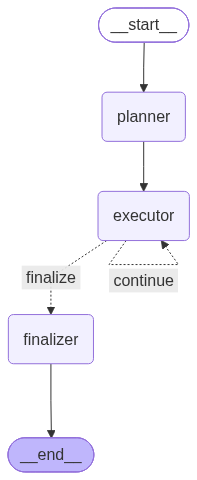

In [10]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
inputs = {
    "input": research_request
}

config = {"recursion_limit": 20}

state_history = []

for mode, event in graph.stream(
    inputs,
    config=config,
    stream_mode=["updates", "values"],
):
    if mode == "values":
        state_history.append(event)
        continue

    for node_name, value in event.items():
        if node_name == "planner":
            print("\n[계획]")
            for step in value["plan"]:
                print(f"- {step}")

        elif node_name == "executor":
            step, result = value["past_steps"][-1]
            print(f"\n[실행] {step}")
            print(result)

        elif node_name == "finalizer":
            print("\n[최종 응답]")
            print(value["response"])

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.



[계획]
- 2025년 하반기 및 2026년 글로벌 IT 리서치 기관(Gartner, IDC 등)의 생성형 AI 기술 트렌드 전망 조사
- 2026년 핵심 생성형 AI 트렌드 후보(AI 에이전트, 멀티모달, 온디바이스 AI, 소형언어모델, AI 윤리 및 거버넌스 등)별 기술적 특징 조사
- 주요 빅테크 기업(OpenAI, Google, Microsoft 등)의 2026년 생성형 AI 관련 로드맵 및 산업별 도입 사례 조사
- 선정할 주요 생성형 AI 트렌드 5개에 대한 시장 영향력, 예상 변화 및 신뢰할 수 있는 수치/통계 근거 수집

[실행] 2025년 하반기 및 2026년 글로벌 IT 리서치 기관(Gartner, IDC 등)의 생성형 AI 기술 트렌드 전망 조사
2025년 하반기 및 2026년 글로벌 IT 리서치 기관(Gartner, IDC)의 생성형 AI 기술 트렌드 전망을 정리한 조사 결과입니다.

---

### 1. 주요 조사 결과 요약

* **기술 패러다임 전환 (Assistants → Agentic AI)**: 단순 대화·생성형 보조 도구(AI Assistant) 단계에서, 목표를 스스로 설정하고 작업을 자율 실행하는 **'에이전틱 AI(Agentic AI) 및 다중 에이전트(Multiagent) 오케스트레이션'** 체계로 확산되고 있습니다.
* **실질적 ROI 및 거버넌스 확보 중요성**: 단순 PoC(개념 검증) 수준을 넘어 **ROI(투자 대비 효과) 검증 및 거버넌스/AI 보안**이 핵심 과제로 떠올랐으며, 거버넌스 미비 시 대규모 프로젝트 중단 위험이 예견됩니다.

---

### 2. 기관별 세부 전망 및 근거

#### 1) Gartner (가트너)
* **2026년 10대 전략 기술 트렌드 (Top Strategic Technology Trends for 2026)**
  * **에이전틱 AI 및 다중 에이전트 시스템(Multiagent Systems)**: 2025년 상용 앱의 5% 미만에 그쳤던 작업 특화 AI 에이전트 탑